# 02 · Baseline machine learning cổ điển

Bốn phương pháp học từ dữ liệu nhưng **không dùng mạng nơ-ron đồ thị**. Chúng trả lời câu hỏi của Thầy: TAS-GNN so với machine learning thông thường thì thế nào?

| Phương pháp | Họ | Ý tưởng | Dùng thời gian? |
|---|---|---|---|
| **User-KNN** | Lọc cộng tác theo láng giềng | Người giống bạn đã ghé đâu | Không |
| **Item-KNN** | Lọc cộng tác theo láng giềng | Nơi nào hay được ghé cùng nơi bạn đã ghé | Không |
| **BPR-MF** | Phân rã ma trận | Học vector 64 chiều cho người dùng và địa điểm | Không |
| **Gradient Boosting** | Học có giám sát trên đặc trưng | Cây quyết định tăng cường dự đoán xác suất ghé | Có (giờ, thứ) |

Mã của từng mô hình nằm trong `src/baselines/`. Cùng giao thức với notebook 01.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm thư mục gốc dự án (nơi có src/benchmark_ml.py) dù notebook được mở từ đâu.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "benchmark_ml.py").is_file())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
import benchmark_ml as bm

warnings.filterwarnings("ignore")
INK, SEA, CORAL, SAND, SKY, MUTED = "#1d2b2f", "#1f6f78", "#c8553d", "#b8860b", "#3d6a9e", "#9aa5a8"
GROUP_COLOR = {"heuristic": SAND, "ml": SKY, "gnn": SEA}
GROUP_NAME = {"heuristic": "Heuristic", "ml": "Machine learning cổ điển", "gnn": "Mạng nơ-ron đồ thị"}
CATEGORY_NAME = {"cafe": "Cà phê", "restaurant": "Ăn uống", "hotel": "Lưu trú", "tourist_spot": "Tham quan"}
CATEGORY_COLOR = {"cafe": SAND, "restaurant": CORAL, "hotel": SKY, "tourist_spot": SEA}
LABEL = {key: label for key, label, _ in bm.MODELS}
GROUP = {key: group for key, _, group in bm.MODELS}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.edgecolor": MUTED, "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})

bench = bm.prepare()
print(f"{bench.n_users:,} người dùng · {bench.n_items:,} địa điểm · {len(bench.events):,} lượt check-in")
print(f"Train {len(bench.train):,} · Test {len(bench.test):,} · Test tại địa điểm mới (được chấm) {len(bench.novel):,}")


def color_of(key):
    return CORAL if key == "tas_gnn" else GROUP_COLOR[GROUP[key]]


def show_results(ranks, title, metric="HR@10"):
    """Bảng chỉ số (%) và biểu đồ cột của các phương pháp đã có kết quả."""
    table = bm.results_table(ranks)
    display(table.drop(columns=["model", "group"]).rename(columns={"label": "Phương pháp"}).set_index("Phương pháp")
            .style.format("{:.2f}").background_gradient(cmap="YlGn", axis=0))
    ordered = table.sort_values(metric)
    fig, ax = plt.subplots(figsize=(9, .5 * len(ordered) + 1.4))
    bars = ax.barh(ordered.label, ordered[metric], color=[color_of(k) for k in ordered.model])
    ax.bar_label(bars, fmt="%.2f%%", padding=4)
    ax.set(xlabel=f"{metric} (%)", title=title, xlim=(0, ordered[metric].max() * 1.18))
    ax.grid(axis="y", visible=False)
    plt.show()
    return table


1,500 người dùng · 996 địa điểm · 36,210 lượt check-in
Train 28,360 · Test 7,850 · Test tại địa điểm mới (được chấm) 6,811


## 1. Ma trận người dùng × địa điểm

Ba phương pháp đầu chỉ nhìn ma trận này: ô (*u*, *j*) là số lần người dùng *u* ghé địa điểm *j* trong tập train.

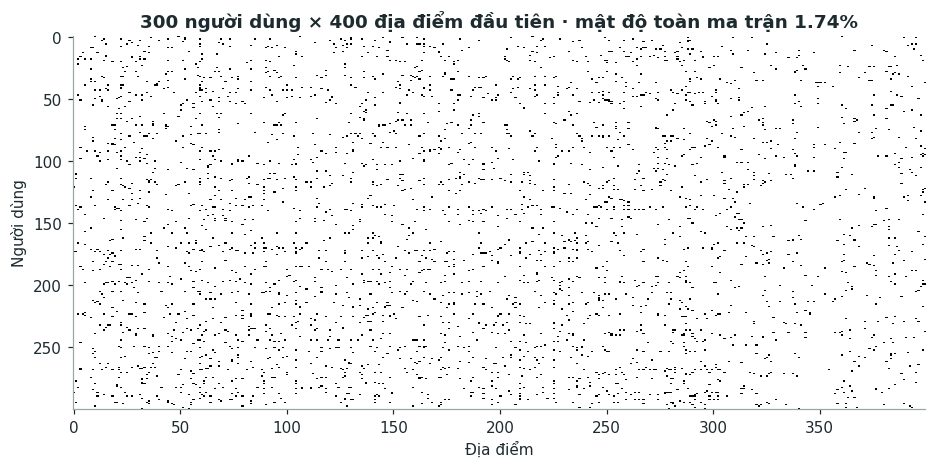

Ma trận 1,500 × 996, 25,980 ô khác 0. Mỗi người dùng ghé trung bình 17.3 địa điểm khác nhau.


In [2]:
C = bench.counts
density = C.nnz / (C.shape[0] * C.shape[1])
sub = (C[:300, :400] > 0).toarray()
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.imshow(sub, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set(title=f"300 người dùng × 400 địa điểm đầu tiên · mật độ toàn ma trận {density:.2%}", xlabel="Địa điểm", ylabel="Người dùng")
ax.grid(False)
plt.show()
print(f"Ma trận {C.shape[0]:,} × {C.shape[1]:,}, {C.nnz:,} ô khác 0. Mỗi người dùng ghé trung bình {C.nnz / C.shape[0]:.1f} địa điểm khác nhau.")

## 2. User-KNN

Độ giống nhau giữa hai người dùng là cosine giữa hai hàng của ma trận. Điểm của địa điểm *j* với người dùng *u* là trung bình có trọng số lượt ghé *j* của những người giống *u*.

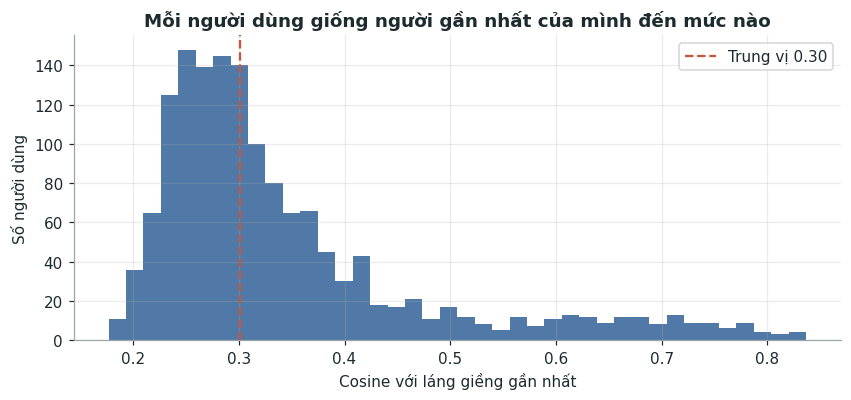

User-KNN: huấn luyện 0.02 s · HR@10 10.35%


In [3]:
from baselines.user_cf import UserCF

ranks, seconds = {}, {}
start = time.perf_counter()
user_knn = UserCF().fit(bench.counts)
seconds["user_knn"] = time.perf_counter() - start
ranks["user_knn"] = bm.evaluate(bench, lambda chunk: user_knn.predict(chunk.u.to_numpy(int)))
bm.save_ranks("user_knn", ranks["user_knn"], seconds["user_knn"], "cosine trên ma trận số lượt ghé")

best_match = user_knn.W.max(1)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(best_match, bins=40, color=SKY, alpha=.9)
ax.axvline(np.median(best_match), color=CORAL, ls="--", label=f"Trung vị {np.median(best_match):.2f}")
ax.set(title="Mỗi người dùng giống người gần nhất của mình đến mức nào", xlabel="Cosine với láng giềng gần nhất", ylabel="Số người dùng")
ax.legend(); plt.show()
print(f"User-KNN: huấn luyện {seconds['user_knn']:.2f} s · HR@10 {bm.rank_metrics(ranks['user_knn'])['HR@10']:.2%}")

## 3. Item-KNN

Ngược lại với User-KNN: độ giống nhau tính giữa hai **địa điểm** (hai cột), giữ 50 láng giềng mạnh nhất của mỗi địa điểm. Điểm của *j* là tổng độ giống giữa *j* và các nơi người dùng đã ghé.

In [4]:
from baselines.item_knn import ItemKNN

start = time.perf_counter()
item_knn = ItemKNN(k=50).fit(bench.counts)
seconds["item_knn"] = time.perf_counter() - start
ranks["item_knn"] = bm.evaluate(bench, lambda chunk: item_knn.predict(chunk.u.to_numpy(int)))
bm.save_ranks("item_knn", ranks["item_knn"], seconds["item_knn"], "cosine, 50 láng giềng")

anchor = int(np.argmax(bench.popularity))
neighbours = np.argsort(-item_knn.sim[anchor])[:8]
print(f"Láng giềng của địa điểm đông nhất: {bench.pois.name[anchor]} ({CATEGORY_NAME[bench.pois.category[anchor]]}, {bench.pois.district[anchor]})")
display(pd.DataFrame({"Địa điểm": bench.pois.name[neighbours].values, "Loại": bench.pois.category[neighbours].map(CATEGORY_NAME).values,
                      "Quận": bench.pois.district[neighbours].values, "Cosine": item_knn.sim[anchor, neighbours].round(3)}))
print(f"Item-KNN: huấn luyện {seconds['item_knn']:.2f} s · HR@10 {bm.rank_metrics(ranks['item_knn'])['HR@10']:.2%}")

Láng giềng của địa điểm đông nhất: Cafe Anh (Cà phê, Cẩm Lệ)


,Địa điểm,Loại,Quận,Cosine
0,CaPhe Chau,Cà phê,Cẩm Lệ,0.834
1,Cafe New Style,Cà phê,Cẩm Lệ,0.756
2,Cà phê Thật,Cà phê,Cẩm Lệ,0.688
3,Cafe Yen Nhi,Cà phê,Cẩm Lệ,0.643
4,CaPhe Win Win,Cà phê,Cẩm Lệ,0.543
5,QanCafe Giai Khat,Cà phê,Cẩm Lệ,0.542
6,CaPhe Rang Dong,Cà phê,Cẩm Lệ,0.534
7,Chùa Nam Sơn,Tham quan,Cẩm Lệ,0.377


Item-KNN: huấn luyện 0.02 s · HR@10 9.10%


## 4. BPR-MF

Phân rã ma trận với hàm mất mát Bayesian Personalized Ranking: mỗi người dùng và mỗi địa điểm có một vector 64 chiều, huấn luyện sao cho nơi đã ghé có điểm cao hơn một nơi chưa ghé lấy ngẫu nhiên.

Số epoch và tốc độ học được chọn trên **validation cắt từ train** (phần cuối của mỗi người dùng trong train), không đụng tới test. Sau đó mô hình được huấn luyện lại trên toàn bộ train.

    epochs=30 lr=0.005: validation HR@10 0.0649


    epochs=100 lr=0.005: validation HR@10 0.0458


    epochs=30 lr=0.02: validation HR@10 0.0455


    epochs=100 lr=0.02: validation HR@10 0.0380


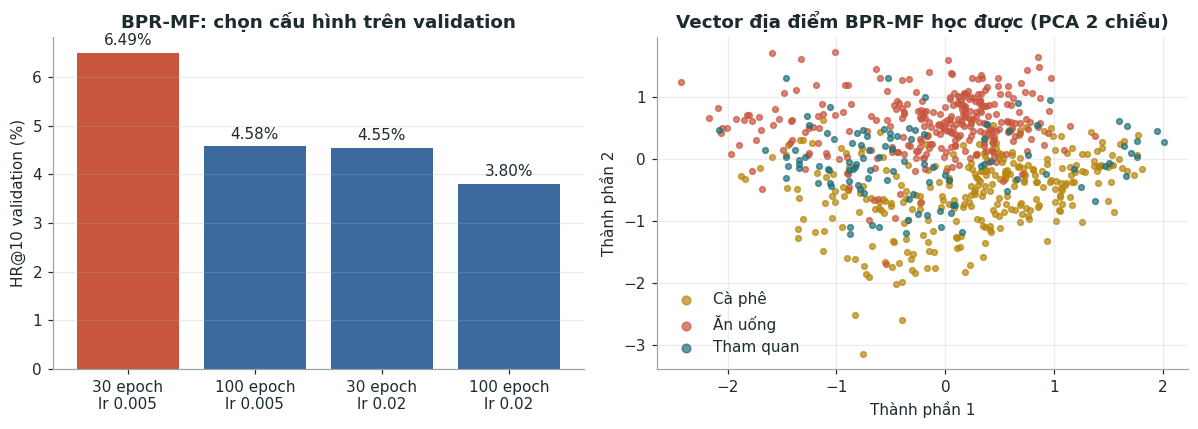

BPR-MF (30 epoch, lr 0.005): 47.2 s kể cả dò tham số · HR@10 6.24%


In [5]:
start = time.perf_counter()
bpr, bpr_config, bpr_trials = bm.tune_bpr(bench)
seconds["bpr_mf"] = time.perf_counter() - start
ranks["bpr_mf"] = bm.evaluate(bench, lambda chunk: bpr.predict(chunk.u.to_numpy(int)))
bm.save_ranks("bpr_mf", ranks["bpr_mf"], seconds["bpr_mf"], bm.bpr_note(bpr_config))

trials = pd.DataFrame(bpr_trials)
labels = [f"{int(e)} epoch\nlr {lr}" for e, lr in zip(trials.epochs, trials.lr)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(labels, trials["HR@10"] * 100, color=[CORAL if (e, lr) == bpr_config else SKY for e, lr in zip(trials.epochs, trials.lr)])
axes[0].bar_label(bars, fmt="%.2f%%", padding=3)
axes[0].set(title="BPR-MF: chọn cấu hình trên validation", ylabel="HR@10 validation (%)")
axes[0].grid(axis="x", visible=False)

from sklearn.decomposition import PCA
visited = bench.popularity > 0
xy = PCA(2, random_state=0).fit_transform(bpr.V[visited])
for category, name in CATEGORY_NAME.items():
    pick = (bench.pois.category[visited] == category).to_numpy()
    if pick.any():
        axes[1].scatter(xy[pick, 0], xy[pick, 1], s=14, alpha=.7, color=CATEGORY_COLOR[category], label=name)
axes[1].set(title="Vector địa điểm BPR-MF học được (PCA 2 chiều)", xlabel="Thành phần 1", ylabel="Thành phần 2")
axes[1].legend(frameon=False, markerscale=1.5)
plt.tight_layout(); plt.show()
print(f"BPR-MF ({bpr_config[0]} epoch, lr {bpr_config[1]}): {seconds['bpr_mf']:.1f} s kể cả dò tham số · HR@10 {bm.rank_metrics(ranks['bpr_mf'])['HR@10']:.2%}")

## 5. Gradient Boosting trên đặc trưng

Đây là baseline machine learning "truyền thống" nhất: biến bài toán gợi ý thành **phân loại nhị phân**. Mỗi bộ (người dùng, địa điểm, giờ, thứ) là một dòng đặc trưng; nhãn 1 nếu người dùng thật sự ghé, kèm 4 mẫu âm lấy ngẫu nhiên.

Để không rò rỉ nhãn, đặc trưng của người dùng (tâm hoạt động, tỉ lệ từng loại địa điểm) chỉ tính từ **phần lịch sử đứng trước** các sự kiện được gán nhãn. Độ sâu cây được chọn trên validation cắt từ train.

In [6]:
from baselines.feature_gbm import FEATURES

start = time.perf_counter()
gbm = bm.tune_gbm(bench)
seconds["feature_gbm"] = time.perf_counter() - start
print(f"Tập huấn luyện: {gbm.rows:,} dòng × {len(FEATURES)} đặc trưng · tỉ lệ dương {gbm.y.mean():.1%} · max_depth chọn được = {gbm.depth}")
start = time.perf_counter()
ranks["feature_gbm"] = bm.evaluate(bench, gbm.scorer)
print(f"Chấm {len(ranks['feature_gbm']):,} sự kiện × {bench.n_items} ứng viên trong {time.perf_counter() - start:.0f} s")
bm.save_ranks("feature_gbm", ranks["feature_gbm"], seconds["feature_gbm"], bm.gbm_note(gbm))
print(f"Gradient Boosting: HR@10 {bm.rank_metrics(ranks['feature_gbm'])['HR@10']:.2%}")

    max_depth=4: validation HR@10 0.1129


    max_depth=8: validation HR@10 0.1086


Tập huấn luyện: 39,435 dòng × 13 đặc trưng · tỉ lệ dương 20.0% · max_depth chọn được = 4


Chấm 6,811 sự kiện × 996 ứng viên trong 23 s
Gradient Boosting: HR@10 13.93%


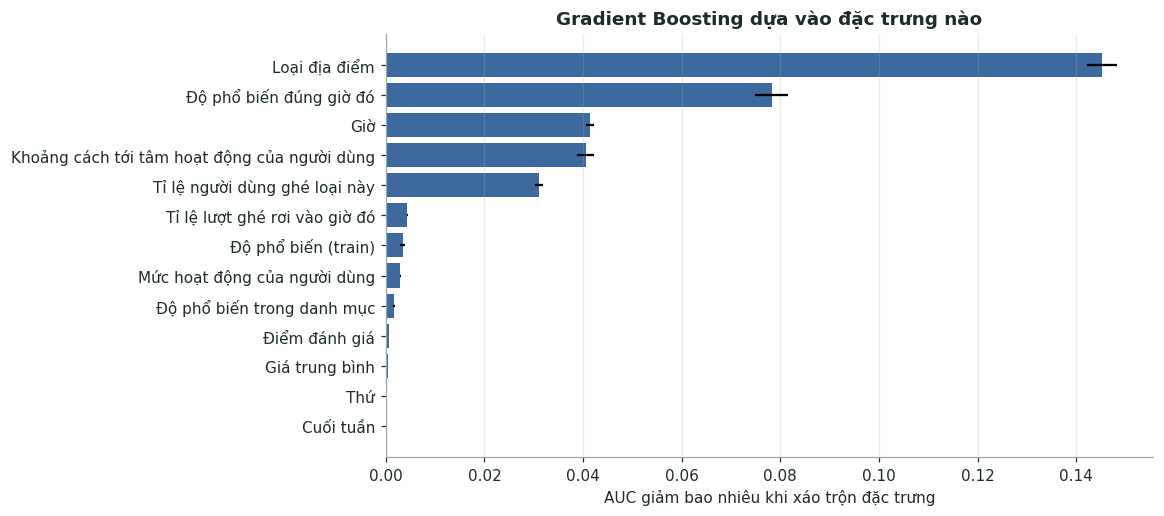

Chọn độ sâu cây trên validation: max_depth=4 → HR@10 11.29%, max_depth=8 → HR@10 10.86%


In [7]:
from sklearn.inspection import permutation_importance

FEATURE_NAME = {"hour": "Giờ", "weekday": "Thứ", "weekend": "Cuối tuần", "category": "Loại địa điểm", "log_popularity": "Độ phổ biến (train)",
                "log_hour_popularity": "Độ phổ biến đúng giờ đó", "hour_share": "Tỉ lệ lượt ghé rơi vào giờ đó",
                "km_from_user_centre": "Khoảng cách tới tâm hoạt động của người dùng", "user_category_share": "Tỉ lệ người dùng ghé loại này",
                "log_user_events": "Mức hoạt động của người dùng", "rating": "Điểm đánh giá", "log_price": "Giá trung bình",
                "catalog_popularity": "Độ phổ biến trong danh mục"}
pick = np.random.default_rng(0).choice(len(gbm.y), size=min(20000, len(gbm.y)), replace=False)
importance = permutation_importance(gbm.model, gbm.X[pick], gbm.y[pick], scoring="roc_auc", n_repeats=3, random_state=0)
order = np.argsort(importance.importances_mean)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([FEATURE_NAME[FEATURES[i]] for i in order], importance.importances_mean[order], xerr=importance.importances_std[order], color=SKY)
ax.set(title="Gradient Boosting dựa vào đặc trưng nào", xlabel="AUC giảm bao nhiêu khi xáo trộn đặc trưng")
ax.grid(axis="y", visible=False)
plt.show()

trials = pd.DataFrame(gbm.trials)
print("Chọn độ sâu cây trên validation:", ", ".join(f"max_depth={int(d)} → HR@10 {hr:.2%}" for d, hr in zip(trials.max_depth, trials["HR@10"])))

## 6. Bốn phương pháp đặt cạnh nhau

Nếu đã chạy notebook 01, ba baseline heuristic được nạp lại để so cùng.

,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20
Phương pháp,,,,,,,,,
Phổ biến chung,2.17,1.01,0.65,6.12,2.29,1.17,11.19,3.56,1.51
Phổ biến theo giờ,6.33,3.78,2.95,10.53,5.13,3.50,16.37,6.61,3.91
Giờ × khoảng cách liền trước,9.90,6.54,5.44,14.64,8.05,6.05,21.79,9.85,6.54
User-KNN,6.33,4.09,3.36,10.35,5.38,3.89,15.49,6.67,4.24
Item-KNN,5.77,3.93,3.33,9.10,5.00,3.76,13.82,6.17,4.08
BPR-MF,4.07,2.63,2.16,6.24,3.32,2.44,9.93,4.24,2.69
Gradient Boosting (đặc trưng),7.71,4.90,3.98,13.93,6.90,4.80,20.44,8.54,5.26


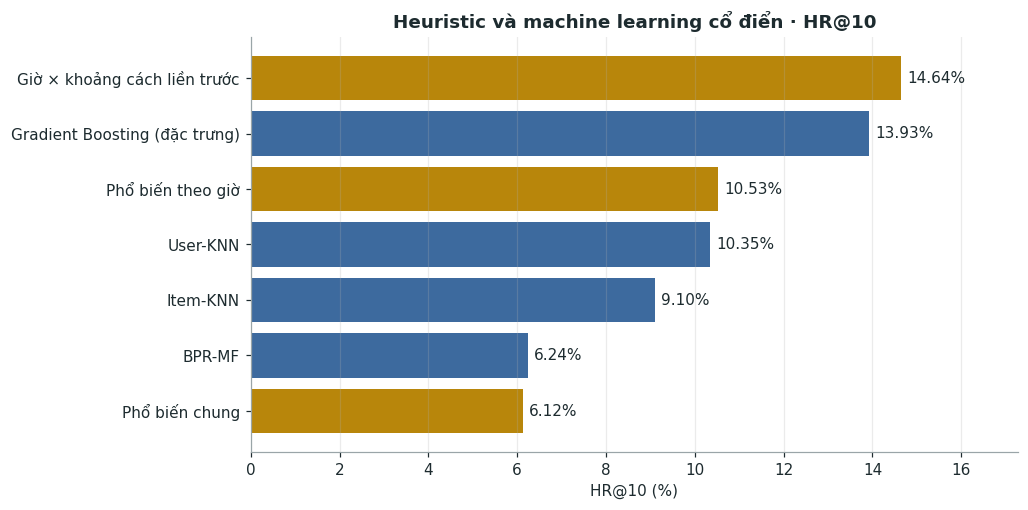

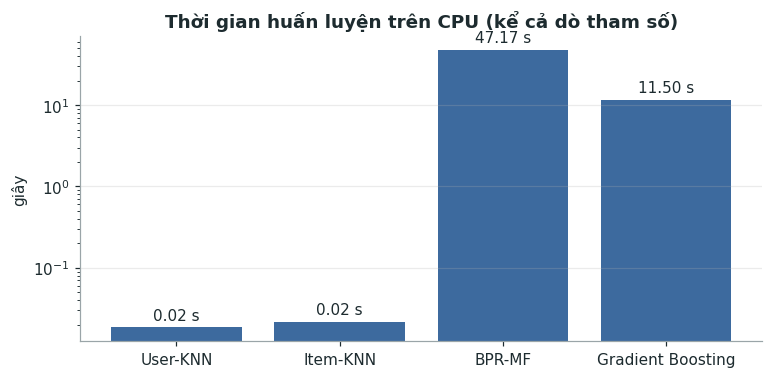

In [8]:
saved, _, _ = bm.load_ranks()
both = {key: saved[key] for key in saved if GROUP[key] in ("heuristic", "ml")}
table = show_results(both, "Heuristic và machine learning cổ điển · HR@10")

fig, ax = plt.subplots(figsize=(8, 3.6))
keys = [k for k in ("user_knn", "item_knn", "bpr_mf", "feature_gbm")]
bars = ax.bar([LABEL[k].replace(" (đặc trưng)", "") for k in keys], [seconds[k] for k in keys], color=SKY)
ax.bar_label(bars, labels=[f"{seconds[k]:.2f} s" for k in keys], padding=3)
ax.set(title="Thời gian huấn luyện trên CPU (kể cả dò tham số)", ylabel="giây", yscale="log")
ax.grid(axis="x", visible=False)
plt.show()

## Nhận xét

- Ba phương pháp **lọc cộng tác** (User-KNN, Item-KNN, BPR-MF) không biết gì về thời gian và vị trí. Với ma trận thưa như ở trên, cả ba đều thấp hơn baseline phổ biến theo giờ.
- **Gradient Boosting** mạnh hơn hẳn vì được cấp trực tiếp các đặc trưng thời gian, khoảng cách và sở thích theo loại. Biểu đồ đặc trưng cho thấy nó dựa nhiều nhất vào đâu.
- Đây là mốc mà TAS-GNN phải được so với một cách thẳng thắn.

Tiếp theo: `03_so_sanh_voi_gnn.ipynb`.